# XGrammar-2：动态工具集合与真实模型复现

论文：**XGrammar-2: Dynamic and Efficient Structured Generation Engine for Agentic LLMs**（ACM CAIS 2026），[arXiv v4](https://arxiv.org/abs/2601.04426v4)。作者代码固定为 v0.2.0；模型固定为 Qwen3-0.6B；数据固定为 BFCL v3 simple。

本项目复现 §4.1 的跨语法缓存机制，并在论文同款小模型上补充本地 JSON 工具调用实验。Apple M3 Pro 上的 CPU/Metal 实验覆盖核心机制，不覆盖 SGLang/CUDA 服务器吞吐、CONFETTI 全集或论文全部图表。

In [1]:
from pathlib import Path
import sys, json, subprocess
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "source_manifest.json").exists():
    ROOT = ROOT / "outputs" / "xgrammar2_replication"
PYTHON = ROOT / ".venv" / "bin" / "python"
if not PYTHON.exists():
    PYTHON = Path(sys.executable)

def run_script(name, *arguments):
    process = subprocess.Popen([str(PYTHON), str(ROOT / name), *arguments], cwd=ROOT,
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in process.stdout:
        print(line, end="", flush=True)
    if process.wait() != 0:
        raise RuntimeError(f"{name} failed")

print("Project:", ROOT.name)
display(json.loads((ROOT / "source_manifest.json").read_text()))

Project: xgrammar2_replication


{'paper': 'https://arxiv.org/abs/2601.04426',
 'paper_version': 'v4',
 'doi': '10.1145/3786335.3813124',
 'engine_version': '0.2.0',
 'engine_revision': '5433fdbea7003eea61cb863768a05fb8da3bf919',
 'engine_archive_url': 'https://codeload.github.com/mlc-ai/xgrammar/zip/5433fdbea7003eea61cb863768a05fb8da3bf919',
 'engine_archive_sha256': 'b5fc16b0cfedb9350b6529c058c1b736230817804649d977b05a09550a9a40e3',
 'model_repo': 'Qwen/Qwen3-0.6B',
 'model_revision': 'c1899de289a04d12100db370d81485cdf75e47ca',
 'model_license': 'apache-2.0',
 'model_files': ['.gitattributes',
  'LICENSE',
  'README.md',
  'config.json',
  'generation_config.json',
  'merges.txt',
  'model.safetensors',
  'tokenizer.json',
  'tokenizer_config.json',
  'vocab.json']}

## 1. 固定来源与实验设计

下载器只获取固定公开版本；原始数据、模型权重与作者源码不进入公开仓库。动态实验每次更换工具组合，完整语法哈希必须不重复；静态实验复用同一语法。缓存开关使用同一请求顺序，单线程编译，独立重复三次。

In [2]:
display(json.loads((ROOT / "inputs" / "data_provenance.json").read_text()))
display(json.loads((ROOT / "model_manifest.json").read_text()))

{'schema_version': 1,
 'dataset': 'BFCL v3 simple (Python, single function)',
 'source_repository': 'https://github.com/ShishirPatil/gorilla',
 'source_revision': 'cd9429ccf3d4d04156affe883c495b3b047e6b64',
 'source_revision_date': '2025-08-06T23:50:01Z',
 'selection_reason': 'Last V3 repository snapshot immediately preceding the V4 rename commit 58f57e9124ea981403792dd51e00a6577e621fae; current repository head uses V4 names.',
 'observed_current_head': '6ea57973c7a6097fd7c5915698c54c17c5b1b6c8',
 'observed_current_head_date': '2026-03-23T11:40:47Z',
 'retrieved_at_utc': '2026-10-15T15:20:39.570323+00:00',
 'license': {'spdx': 'Apache-2.0',
  'repository_license_url': 'https://github.com/ShishirPatil/gorilla/blob/cd9429ccf3d4d04156affe883c495b3b047e6b64/LICENSE',
  'author_dataset_card_url': 'https://huggingface.co/datasets/gorilla-llm/Berkeley-Function-Calling-Leaderboard',
  'redistribution': 'Author dataset card specifies Apache-2.0; preserve license and attribution if redistributin

{'repo': 'Qwen/Qwen3-0.6B',
 'revision': 'c1899de289a04d12100db370d81485cdf75e47ca',
 'license': 'apache-2.0',
 'assets': {'LICENSE': {'sha256': '832dd9e00a68dd83b3c3fb9f5588dad7dcf337a0db50f7d9483f310cd292e92e',
   'bytes': 11343},
  'README.md': {'sha256': '1ab64a26fcb3b461423b89a433a8c858f1bf8d4086f979cbb3ff878d47cf20e9',
   'bytes': 13965},
  'config.json': {'sha256': '660db3b73d788119c04535e48cf9be5f55bc3100841a718637ae695b442f27dd',
   'bytes': 726},
  'generation_config.json': {'sha256': '2325da0f15bb848e018c5ae071b7943332e9f871d6b60e2ed22ca97d4cb993d2',
   'bytes': 239},
  'merges.txt': {'sha256': '8831e4f1a044471340f7c0a83d7bd71306a5b867e95fd870f74d0c5308a904d5',
   'bytes': 1671853},
  'model.safetensors': {'sha256': 'f47f71177f32bcd101b7573ec9171e6a57f4f4d31148d38e382306f42996874b',
   'bytes': 1503300328},
  'tokenizer.json': {'sha256': 'aeb13307a71acd8fe81861d94ad54ab689df773318809eed3cbe794b4492dae4',
   'bytes': 11422654},
  'tokenizer_config.json': {'sha256': 'd5d09f07b

## 2. 跨语法缓存实验

10、50、100、200 个真实工具，每种条件 20 个请求、3 次重复。冷启动和后续请求分开统计；不把完整语法缓存命中混同于动态子结构复用。

In [3]:
run_script("benchmark_runner.py", "--counts", "10,50,100,200", "--requests", "20", "--repeats", "3", "--tokenizer", "models/Qwen3-0.6B", "--local-files-only")

XGrammar 0.2.0; CPU max_threads=1; 399 public tools; counts=[10, 50, 100, 200]
repeat 1/3 static tools=10 request 1/20: off=124.84 ms on=23.99 ms reset=23.78 ms
repeat 1/3 static tools=10 request 2/20: off=119.89 ms on=0.04 ms reset=23.83 ms
repeat 1/3 static tools=10 request 3/20: off=119.95 ms on=0.06 ms reset=24.40 ms
repeat 1/3 static tools=10 request 4/20: off=120.65 ms on=0.05 ms reset=24.41 ms
repeat 1/3 static tools=10 request 5/20: off=121.39 ms on=0.05 ms reset=23.65 ms
repeat 1/3 static tools=10 request 6/20: off=119.18 ms on=0.03 ms reset=23.30 ms
repeat 1/3 static tools=10 request 7/20: off=118.81 ms on=0.05 ms reset=23.78 ms
repeat 1/3 static tools=10 request 8/20: off=117.95 ms on=0.05 ms reset=23.83 ms
repeat 1/3 static tools=10 request 9/20: off=116.95 ms on=0.03 ms reset=23.48 ms
repeat 1/3 static tools=10 request 10/20: off=118.18 ms on=0.03 ms reset=23.25 ms
repeat 1/3 static tools=10 request 11/20: off=118.96 ms on=0.04 ms reset=23.33 ms
repeat 1/3 static tools=10 

## 3. Qwen3-0.6B 真实模型验证

预先固定 BFCL v3 simple 前 32 题，逐题比较贪心生成的无约束与 XGrammar 约束模式。格式有效、完成生成和参数答案正确分别报告。评分是本项目的严格参考值检查，不是官方全量 BFCL 排行榜分数。

In [4]:
run_script("generation_runner.py", "--count", "32", "--max-new-tokens", "192")
display(json.loads((ROOT / "results" / "generation_summary.json").read_text()))

Model loaded: Qwen3-0.6B on mps; paired cases=32
1/32 simple_0 unconstrained: complete=True schema=False argument=False tokens=38 seconds=0.86
1/32 simple_0 xgrammar: complete=True schema=True argument=True tokens=34 seconds=0.81
2/32 simple_1 xgrammar: complete=True schema=True argument=True tokens=26 seconds=0.62
2/32 simple_1 unconstrained: complete=True schema=False argument=False tokens=30 seconds=0.67
3/32 simple_2 unconstrained: complete=True schema=False argument=False tokens=38 seconds=1.02
3/32 simple_2 xgrammar: complete=True schema=True argument=True tokens=34 seconds=0.82
4/32 simple_3 xgrammar: complete=True schema=True argument=True tokens=43 seconds=1.02
4/32 simple_3 unconstrained: complete=True schema=False argument=False tokens=47 seconds=1.04
5/32 simple_4 unconstrained: complete=True schema=False argument=False tokens=46 seconds=1.08
5/32 simple_4 xgrammar: complete=True schema=True argument=True tokens=42 seconds=0.98
6/32 simple_5 xgrammar: complete=True schema=T

{'experiment': 'paired_local_json_tool_call',
 'official_bfcl_score': False,
 'sample_rule': 'first N records of pinned BFCL-v3 simple file, no outcome filtering',
 'ids': ['simple_0',
  'simple_1',
  'simple_2',
  'simple_3',
  'simple_4',
  'simple_5',
  'simple_6',
  'simple_7',
  'simple_8',
  'simple_9',
  'simple_10',
  'simple_11',
  'simple_12',
  'simple_13',
  'simple_14',
  'simple_15',
  'simple_16',
  'simple_17',
  'simple_18',
  'simple_19',
  'simple_20',
  'simple_21',
  'simple_22',
  'simple_23',
  'simple_24',
  'simple_25',
  'simple_26',
  'simple_27',
  'simple_28',
  'simple_29',
  'simple_30',
  'simple_31'],
 'max_new_tokens': 192,
 'seed': 20261015,
 'do_sample': False,
 'thinking': False,
 'device': 'mps',
 'dtype': 'torch.float16',
 'platform': 'macOS-27.2-arm64-arm-64bit',
 'packages': {'torch': '2.14.1',
  'xgrammar': '0.2.0',
  'transformers': '4.57.6',
  'jsonschema': '4.26.0'},
 'hf_adapter_change': 'Official v0.2.0 HF initialization; subsequent batch-

## 4. 独立验证与图表

验证器重新读取固定原数据，独立检查严格 JSON、类型、必需参数、答案候选、完整配对和来源哈希。性能结果按本机测量解释。

{
  "scope": "independent offline audit of fixed provenance, paired model generation, CPU cache benchmark and requested notebook",
  "checks": 27153,
  "passed_checks": 27153,
  "all_passed": true
}
Matplotlib is building the font cache; this may take a moment.
Saved cache_comparison.png and generation_comparison.png


{'schema_version': 1,
 'generated_at_utc': '2026-10-15T15:44:49.887952+00:00',
 'scope': 'independent offline audit of fixed provenance, paired model generation, CPU cache benchmark and requested notebook',
 'experiment_runners_imported': False,
 'network_used': False,
 'self_test_only': False,
 'notebook_checked': False,
 'checks': 27153,
 'passed_checks': 27153,
 'all_passed': True,
 'sections': {'independent_checker_self_tests': {'checks': 19,
   'passed': 19,
   'failures': []},
  'pinned_provenance': {'checks': 542, 'passed': 542, 'failures': []},
  'paired_generation': {'checks': 1374, 'passed': 1374, 'failures': []},
  'cache_benchmark': {'checks': 25218, 'passed': 25218, 'failures': []}}}

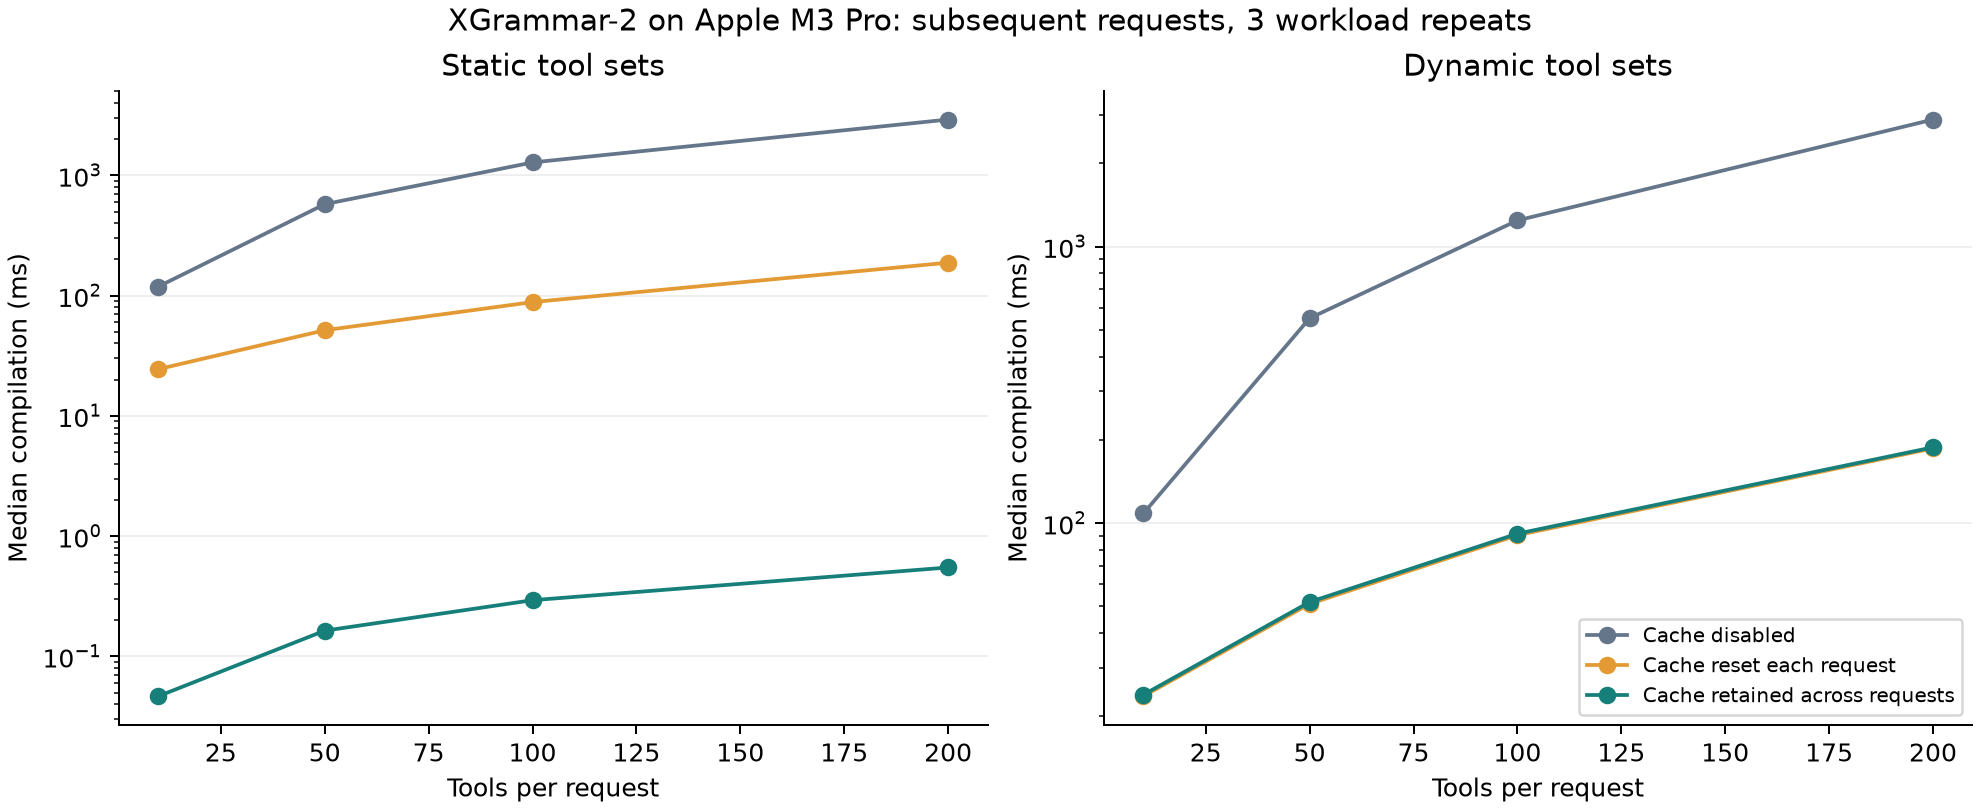

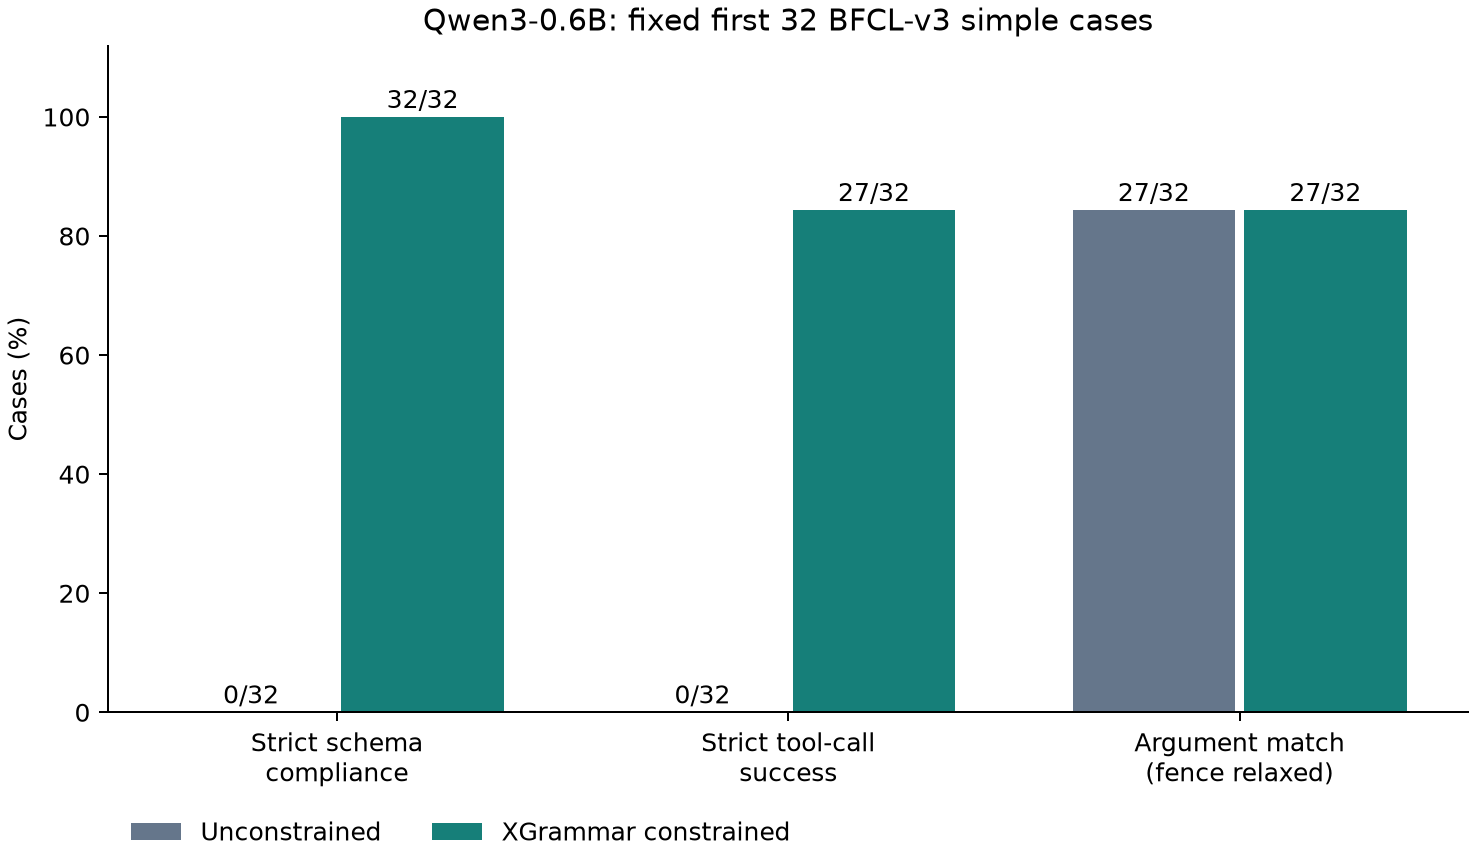

In [5]:
run_script("validate_replication.py")
run_script("plot_results.py")
display(json.loads((ROOT / "results" / "validation_report.json").read_text()))
display(Image(filename=str(ROOT / "results" / "cache_comparison.png")))
display(Image(filename=str(ROOT / "results" / "generation_comparison.png")))

In [6]:
run_script("repeat_generation.py")
display(json.loads((ROOT / "results" / "reproducibility_report.json").read_text()))

Model loaded: Qwen3-0.6B on mps; paired cases=32
1/32 simple_0 unconstrained: complete=True schema=False argument=False tokens=38 seconds=0.86
1/32 simple_0 xgrammar: complete=True schema=True argument=True tokens=34 seconds=0.82
2/32 simple_1 xgrammar: complete=True schema=True argument=True tokens=26 seconds=0.62
2/32 simple_1 unconstrained: complete=True schema=False argument=False tokens=30 seconds=0.66
3/32 simple_2 unconstrained: complete=True schema=False argument=False tokens=38 seconds=0.86
3/32 simple_2 xgrammar: complete=True schema=True argument=True tokens=34 seconds=0.83
4/32 simple_3 xgrammar: complete=True schema=True argument=True tokens=43 seconds=1.03
4/32 simple_3 unconstrained: complete=True schema=False argument=False tokens=47 seconds=1.05
5/32 simple_4 unconstrained: complete=True schema=False argument=False tokens=46 seconds=1.03
5/32 simple_4 xgrammar: complete=True schema=True argument=True tokens=42 seconds=1.00
6/32 simple_5 xgrammar: complete=True schema=T

{'generated_at_utc': '2026-10-15T15:48:52.488999+00:00',
 'protocol': 'same fixed public model, seed, greedy inputs and hardware; new model process',
 'records_per_run': [64, 64],
 'comparison_fields': ['id',
  'mode',
  'output',
  'tokens',
  'completed',
  'json_valid',
  'schema_valid',
  'argument_exact',
  'content_argument_exact',
  'whole_markdown_fence',
  'schema_sha256',
  'prompt_sha256',
  'prompt_tokens_sha256',
  'prompt_token_count'],
 'original_records_sha256': 'f96ee483a044c37f8cb2c284fcc0e0dbae9ae9e29bd157670c20f1613c52c848',
 'replay_records_sha256': 'ec7a5e33d291460efdc19c55f501b395ed63a82d159776d07b7dfa0dcd739b31',
 'timings_expected_to_differ': True,
 'all_deterministic_fields_equal': True,
 'mismatches': [],
 'both_runs_independently_validated': True,
 'limits': 'not a cross-machine, cross-dtype or freshly rebuilt dependency environment guarantee'}